# PRC — Competing Modules: Narrow-Pulse Experiment

**Scenario**
- **c1(t)** — narrow pulses at frequency `f` (small duty cycle), excites P1 only  
- **c2(t)** — identically zero (P2 receives no module-specific drive)  
- **m(t)** — narrow pulses at the **same** period as c1, but with a different amplitude and phase offset  

Competition: P1 inhibits P2 through the latent state (negative `B_u[:, 2]` coupling).

In [6]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path().resolve()))   # adds prc/ to path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import xarray as xr

import prc

## Module Parameters

Two identical modules with 2-D damped-oscillator latent dynamics.  
`A_z` eigenvalues −0.5 ± 2i give an intrinsic damped oscillation at ~2 rad/s.  
The third column of `B_u` (competitor observable) is **negative** → mutual inhibition.

In [7]:
d = 2

# Intrinsic dynamics: eigenvalues -0.5 ± 2i  (damped oscillator)
A_z = np.array([[-0.5, -2.0],
                [ 2.0, -0.5]])

# Input coupling: columns → [c_i,  m,   x_j]
# Competition strength must be < 1.0 for the closed-loop system to be stable.
# (Anti-symmetric mode eigenvalue real part = (-1 + w_c)/2; stable iff w_c < 1.0)
B_u = np.array([[ 1.0,  0.5, -0.8],
                [ 0.0,  0.2,  0.0]])

# Readout: observe first latent dimension through tanh
C_out = np.array([[1.0, 0.0]])
tau_z = 1.0

mod1 = prc.LinearNonlinearModule(d, A_z, B_u, C_out, tau_z=tau_z)
mod2 = prc.LinearNonlinearModule(d, A_z, B_u, C_out, tau_z=tau_z)
system = prc.CompetitiveSystem(mod1, mod2)

print("Module 1:", mod1)
print("Module 2:", mod2)

Module 1: <prc.LinearNonlinearModule object at 0x000002C145CE5450>
Module 2: <prc.LinearNonlinearModule object at 0x000002C145FB4DD0>


## Simulation

| Signal | Description |
|--------|-------------|
| `c1`   | Narrow pulses at `f_pulse` Hz, duty cycle `duty_pulse` |
| `c2`   | Zero (P2 receives no module-specific drive) |
| `m`    | Narrow pulses at the **same** frequency as c1, amplitude `A_m`, phase-shifted by `phi_m` |

Varying `phi_m` controls the *relative timing* between the c1 pulse train and the common-mode m pulse train.

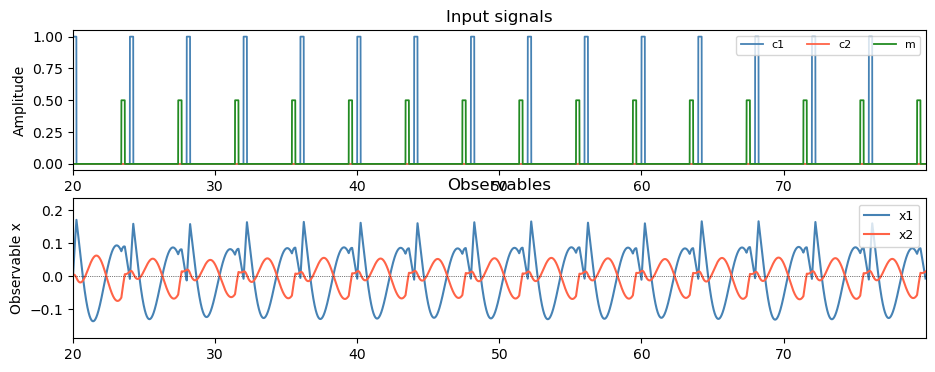

In [33]:
T   = 80.0
dt  = 0.005
t_arr = np.arange(int(round(T / dt))) * dt

f_pulse = 0.25
duty    = 0.06
A_c1    = 1
A_c2    = 0.0
A_m     = 0.5
phi_m   = np.pi * 0.3

# Generate signals
c1 = prc.make_signal(t_arr, amplitude=A_c1/2, frequency=f_pulse, phase=0.0,   duty=duty, offset=A_c1/2)
#c2 = prc.make_signal(t_arr, amplitude=A_c2/2, frequency=0.197, phase=0.0,   duty=duty, offset=A_c2/2)
c2 = xr.DataArray(np.zeros(len(t_arr)), dims=["time"], coords={"time": t_arr})
m  = prc.make_signal(t_arr, amplitude=A_m/2,  frequency=f_pulse, phase=phi_m, duty=duty, offset=A_m/2)

#c1.loc[{'time': slice(20, None)}] = 0

# Run
ds = system.run(c1, c2, m)

t = ds.coords["time"].values

# Visualize
fig = plt.figure(figsize=(11, 4))
gs  = gridspec.GridSpec(2, 1, hspace=0.2)

ax0 = fig.add_subplot(gs[0])
ax0.plot(t, ds["c1"].values, color="steelblue", lw=1.3, label="c1")
ax0.plot(t, ds["c2"].values, color="tomato", lw=1.3, label="c2")
ax0.plot(t, ds["m"].values,  color="forestgreen", lw=1.3, label=f"m")
ax0.set_ylabel("Amplitude"); ax0.set_title("Input signals")
ax0.legend(fontsize=8, ncol=3, loc="upper right")
#ax0.set_xlim(t[0], t[-1])
ax0.set_xlim(20, t[-1])

ax1 = fig.add_subplot(gs[1], sharex=ax0)
ax1.plot(t, ds["x1"].values, color="steelblue", lw=1.5, label="x1")
ax1.plot(t, ds["x2"].values, color="tomato",    lw=1.5, label="x2")
ax1.axhline(0, color="k", lw=0.5, ls=":")
ax1.set_ylabel("Observable x"); ax1.set_title("Observables")
ax1.legend(fontsize=9, loc="upper right")

#plt.savefig("artifacts/prc_pulse_experiment.png", dpi=130, bbox_inches="tight")
plt.show()

 A=0.3  20/200


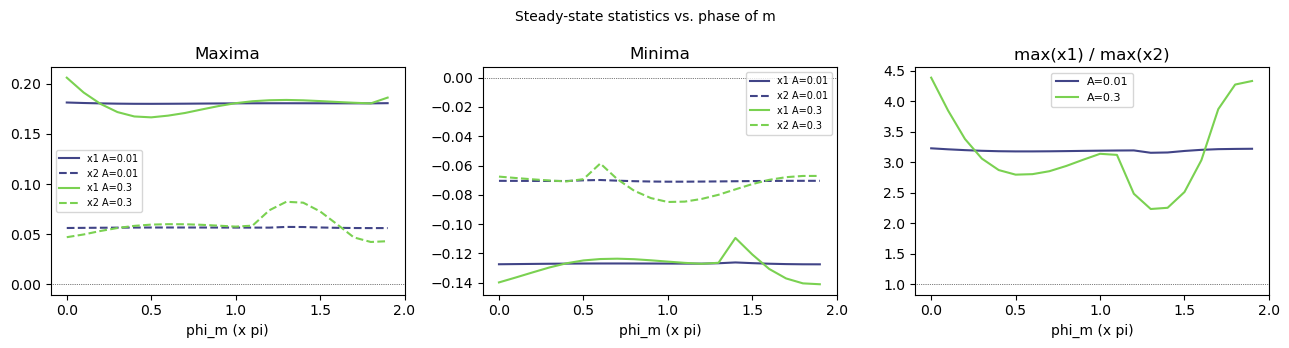

In [38]:
phases     = np.linspace(0, 2 * np.pi, 20, endpoint=False)
amplitudes = [0.01, 0.3]
half       = len(t_arr) // 2

rows = np.empty((len(amplitudes), len(phases), 4))
for ai, A in enumerate(amplitudes):
    for pi, phi in enumerate(phases):
        print(f"\r A={A}  {pi+1}/{len(phases)}", end="", flush=True)
        _m = prc.make_signal(t_arr, amplitude=A/2, frequency=f_pulse, phase=phi, duty=duty, offset=A/2)
        _ds = system.run(c1, c2, _m)
        x1s = _ds["x1"].values[half:]
        x2s = _ds["x2"].values[half:]
        rows[ai, pi] = [x1s.max(), x1s.min(), x2s.max(), x2s.min()]
print()

res = xr.DataArray(
    rows,
    dims=["amplitude", "phase", "stat"],
    coords={
        "amplitude": amplitudes,
        "phase":     phases / np.pi,
        "stat":      ["x1_max", "x1_min", "x2_max", "x2_min"],
    },
)

def plot_res(res):
    phi_ax = res.coords["phase"].values
    xt = [0, 0.5, 1, 1.5, 2]
    colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(res.coords["amplitude"])))

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

    for ax, s1, s2, title in [
        (axes[0], "x1_max", "x2_max", "Maxima"),
        (axes[1], "x1_min", "x2_min", "Minima"),
    ]:
        for c, A in zip(colors, res.coords["amplitude"].values):
            r = res.sel(amplitude=A)
            ax.plot(phi_ax, r.sel(stat=s1), color=c,      lw=1.5, label=f"x1 A={A}")
            ax.plot(phi_ax, r.sel(stat=s2), color=c, lw=1.5, ls="--", label=f"x2 A={A}")
        ax.axhline(0, color="k", lw=0.5, ls=":"); ax.set_xticks(xt)
        ax.set_xlabel("phi_m (x pi)"); ax.set_title(title); ax.legend(fontsize=7)

    ax = axes[2]
    for c, A in zip(colors, res.coords["amplitude"].values):
        r = res.sel(amplitude=A)
        ax.plot(phi_ax, r.sel(stat="x1_max") / r.sel(stat="x2_max"),
                color=c, lw=1.5, label=f"A={A}")
    ax.axhline(1, color="k", lw=0.5, ls=":"); ax.set_xticks(xt)
    ax.set_xlabel("phi_m (x pi)"); ax.set_title("max(x1) / max(x2)"); ax.legend(fontsize=8)

    fig.suptitle("Steady-state statistics vs. phase of m", fontsize=10)
    plt.tight_layout()
    plt.show()

plot_res(res)